In [1]:
# 1. Setup
!pip -q install xgboost
import warnings, json, os
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier, XGBRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
                             precision_recall_curve, confusion_matrix, mean_absolute_error, mean_squared_error, r2_score)
SEED = 7
os.makedirs('outputs', exist_ok=True)
sns.set_theme(style='darkgrid', palette='deep')

In [2]:
# 2. Load data
URL = 'https://raw.githubusercontent.com/IBM/employee-attrition-aif360/master/data/emp_attrition.csv'
try:
    df = pd.read_csv(URL, encoding='utf-8-sig')
except Exception as e:
    print('Download failed, please upload the CSV manually:', e)
    from google.colab import files
    up = files.upload()
    df = pd.read_csv(list(up.keys())[0], encoding='utf-8-sig')
print(df.shape); df.head(3)

(1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0


## 3. Exploratory Data Analysis

Missing values: 0 | Duplicates: 0
Attrition
No     0.839
Yes    0.161
Name: proportion, dtype: float64
OverTime
No     0.104
Yes    0.305
Name: Attrition, dtype: float64


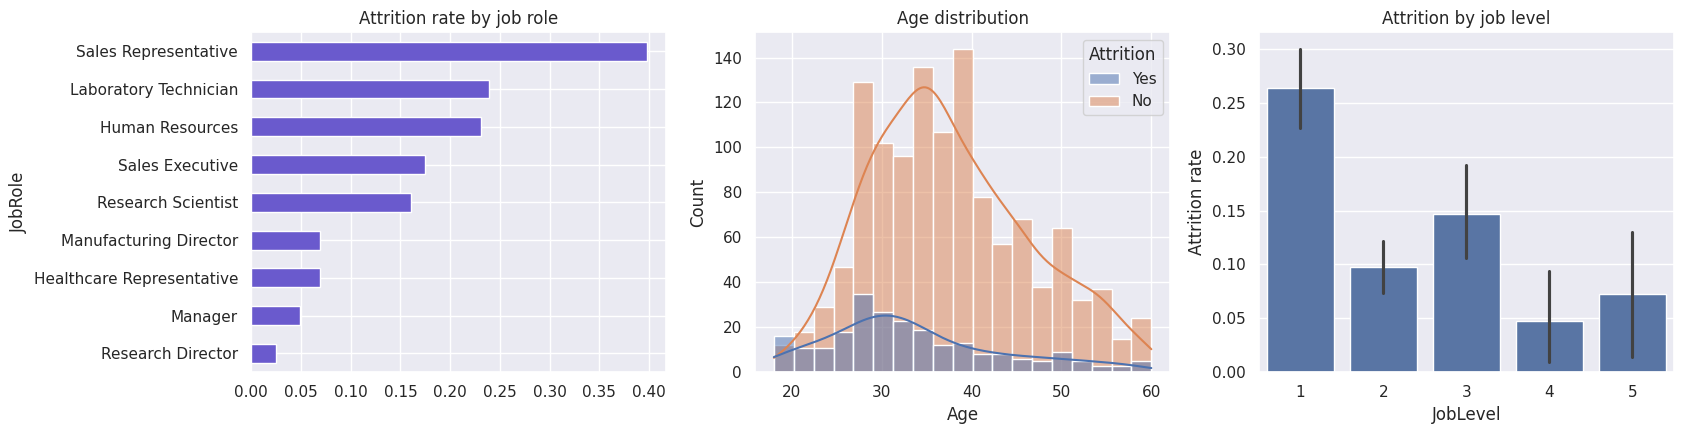

In [3]:
print('Missing values:', int(df.isna().sum().sum()), '| Duplicates:', int(df.duplicated().sum()))
print(df['Attrition'].value_counts(normalize=True).round(3))
grp = df.groupby('JobRole')['Attrition'].apply(lambda s: (s=='Yes').mean()).sort_values()
ot = df.groupby('OverTime')['Attrition'].apply(lambda s: (s=='Yes').mean())
print(ot.round(3))
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
grp.plot(kind='barh', ax=ax[0], color='slateblue'); ax[0].set_title('Attrition rate by job role')
sns.histplot(data=df, x='Age', hue='Attrition', kde=True, ax=ax[1]); ax[1].set_title('Age distribution')
sns.barplot(x='JobLevel', y=(df['Attrition']=='Yes').astype(int), data=df, ax=ax[2]); ax[2].set_ylabel('Attrition rate'); ax[2].set_title('Attrition by job level')
plt.tight_layout(); plt.savefig('outputs/eda.png', dpi=130); plt.show()

## 4. Feature engineering & preprocessing
Extra features created: `IncomeToLevel`, `TenureRatio`, `PromotionGap`, `StabilityScore`, `SatisfactionIndex`.

In [4]:
data = df.drop(columns=[c for c in ['EmployeeCount','EmployeeNumber','StandardHours','Over18'] if c in df.columns]).copy()
data['IncomeToLevel']     = data['MonthlyIncome'] / data['JobLevel']
data['TenureRatio']       = data['YearsAtCompany'] / (data['TotalWorkingYears'] + 1)
data['PromotionGap']      = data['YearsSinceLastPromotion'] / (data['YearsAtCompany'] + 1)
data['StabilityScore']    = data['YearsAtCompany'] / (data['NumCompaniesWorked'] + 1)
data['SatisfactionIndex'] = data[['EnvironmentSatisfaction','JobSatisfaction','RelationshipSatisfaction','WorkLifeBalance']].mean(axis=1)

y = (data['Attrition'] == 'Yes').astype(int); X = data.drop(columns=['Attrition'])
cat_cols = X.select_dtypes(exclude='number').columns.tolist(); num_cols = X.select_dtypes(include='number').columns.tolist()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
print(X_train.shape, X_test.shape)
spw = (y_train==0).sum()/(y_train==1).sum()

def make_pre(scale):
    return ColumnTransformer([('num', StandardScaler() if scale else 'passthrough', num_cols),
                              ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)])

(1102, 35) (368, 35)


## 5. Baseline classifiers

In [5]:
models = {
 'Logistic Regression': Pipeline([('pre', make_pre(True)),  ('clf', LogisticRegression(max_iter=3000, class_weight='balanced', random_state=SEED))]),
 'Decision Tree':       Pipeline([('pre', make_pre(False)), ('clf', DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=SEED))]),
 'Random Forest':       Pipeline([('pre', make_pre(False)), ('clf', RandomForestClassifier(n_estimators=250, class_weight='balanced_subsample', min_samples_leaf=3, random_state=SEED, n_jobs=-1))]),
 'XGBoost':             Pipeline([('pre', make_pre(False)), ('clf', XGBClassifier(n_estimators=250, learning_rate=0.05, max_depth=3, subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw, eval_metric='logloss', random_state=SEED, n_jobs=-1))]),
}
def evaluate(model, Xt, yt, thr=0.5):
    proba = model.predict_proba(Xt)[:, 1]; pred = (proba >= thr).astype(int)
    return {'Accuracy': accuracy_score(yt, pred), 'Precision': precision_score(yt, pred, zero_division=0),
            'Recall': recall_score(yt, pred), 'F1': f1_score(yt, pred), 'ROC-AUC': roc_auc_score(yt, proba)}
base_rows = {}
for n, m in models.items():
    m.fit(X_train, y_train); base_rows[n] = evaluate(m, X_test, y_test)
baseline = pd.DataFrame(base_rows).T.round(3); baseline.to_csv('outputs/baseline_metrics.csv'); baseline

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.769,0.390,0.780,0.520,0.853
Decision Tree,0.799,0.407,0.559,0.471,0.661
Random Forest,0.861,0.654,0.288,0.400,0.837
XGBoost,0.848,0.523,0.576,0.548,0.849


## 6. Repeated-style cross-validation (10-fold stratified)

In [6]:
skf10 = StratifiedKFold(10, shuffle=True, random_state=SEED)
sc = {'accuracy':'accuracy','precision':'precision','recall':'recall','f1':'f1','roc_auc':'roc_auc'}
cv_rows = {}
for n, m in models.items():
    r = cross_validate(m, X_train, y_train, cv=skf10, scoring=sc, n_jobs=-1)
    cv_rows[n] = {k[5:]: f"{v.mean():.3f} ± {v.std():.3f}" for k, v in r.items() if k.startswith('test_')}
cv_table = pd.DataFrame(cv_rows).T; cv_table.to_csv('outputs/cv_metrics.csv'); cv_table

,accuracy,precision,recall,f1,roc_auc
Logistic Regression,0.778 ± 0.049,0.406 ± 0.089,0.720 ± 0.107,0.515 ± 0.087,0.818 ± 0.046
Decision Tree,0.774 ± 0.041,0.381 ± 0.056,0.574 ± 0.127,0.449 ± 0.049,0.726 ± 0.061
Random Forest,0.864 ± 0.023,0.711 ± 0.201,0.291 ± 0.087,0.406 ± 0.104,0.792 ± 0.035
XGBoost,0.844 ± 0.022,0.520 ± 0.075,0.551 ± 0.097,0.530 ± 0.071,0.793 ± 0.040


## 7. Hyperparameter tuning (RandomizedSearchCV, scoring = ROC-AUC)

In [7]:
from scipy.stats import randint, uniform, loguniform
spaces = {
 'Logistic Regression': {'clf__C': loguniform(1e-3, 1e1), 'clf__penalty': ['l2']},
 'Decision Tree': {'clf__max_depth': randint(2, 9), 'clf__min_samples_leaf': randint(3, 40), 'clf__criterion': ['gini','entropy']},
 'Random Forest': {'clf__n_estimators': randint(150, 500), 'clf__max_depth': randint(4, 16), 'clf__min_samples_leaf': randint(1, 10), 'clf__max_features': ['sqrt','log2', 0.4]},
 'XGBoost': {'clf__n_estimators': randint(100, 500), 'clf__max_depth': randint(2, 6), 'clf__learning_rate': loguniform(0.01, 0.2),
             'clf__subsample': uniform(0.6, 0.4), 'clf__colsample_bytree': uniform(0.5, 0.5), 'clf__min_child_weight': randint(1, 8)},
}
tuned, tuned_rows, best_params = {}, {}, {}
for n, m in models.items():
    rs = RandomizedSearchCV(m, spaces[n], n_iter=25, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring='roc_auc', random_state=SEED, n_jobs=-1)
    rs.fit(X_train, y_train); tuned[n] = rs.best_estimator_
    best_params[n] = {k.replace('clf__',''): (round(float(v),4) if isinstance(v,(float,np.floating)) else (int(v) if isinstance(v,(int,np.integer)) else v)) for k, v in rs.best_params_.items()}
    tuned_rows[n] = evaluate(rs.best_estimator_, X_test, y_test)
    print(f'{n}: CV AUC={rs.best_score_:.3f}', best_params[n])
tuned_df = pd.DataFrame(tuned_rows).T.round(3); tuned_df.to_csv('outputs/tuned_metrics.csv'); tuned_df

Logistic Regression: CV AUC=0.809 {'C': 0.2525, 'penalty': 'l2'}
Decision Tree: CV AUC=0.710 {'criterion': 'entropy', 'max_depth': 6, 'min_samples_leaf': 17}
Random Forest: CV AUC=0.786 {'max_depth': 8, 'max_features': 'log2', 'min_samples_leaf': 4, 'n_estimators': 454}
XGBoost: CV AUC=0.796 {'colsample_bytree': 0.6744, 'learning_rate': 0.0229, 'max_depth': 2, 'min_child_weight': 6, 'n_estimators': 491, 'subsample': 0.7256}


,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.766,0.387,0.780,0.517,0.855
Decision Tree,0.745,0.345,0.661,0.453,0.708
Random Forest,0.872,0.667,0.407,0.505,0.844
XGBoost,0.815,0.446,0.627,0.521,0.858


Best model by ROC-AUC: XGBoost
Chosen threshold: 0.571
                Accuracy  Precision  Recall     F1  ROC-AUC
Default (0.50)     0.815      0.446   0.627  0.521    0.858
Tuned (0.57)       0.861      0.565   0.593  0.579    0.858


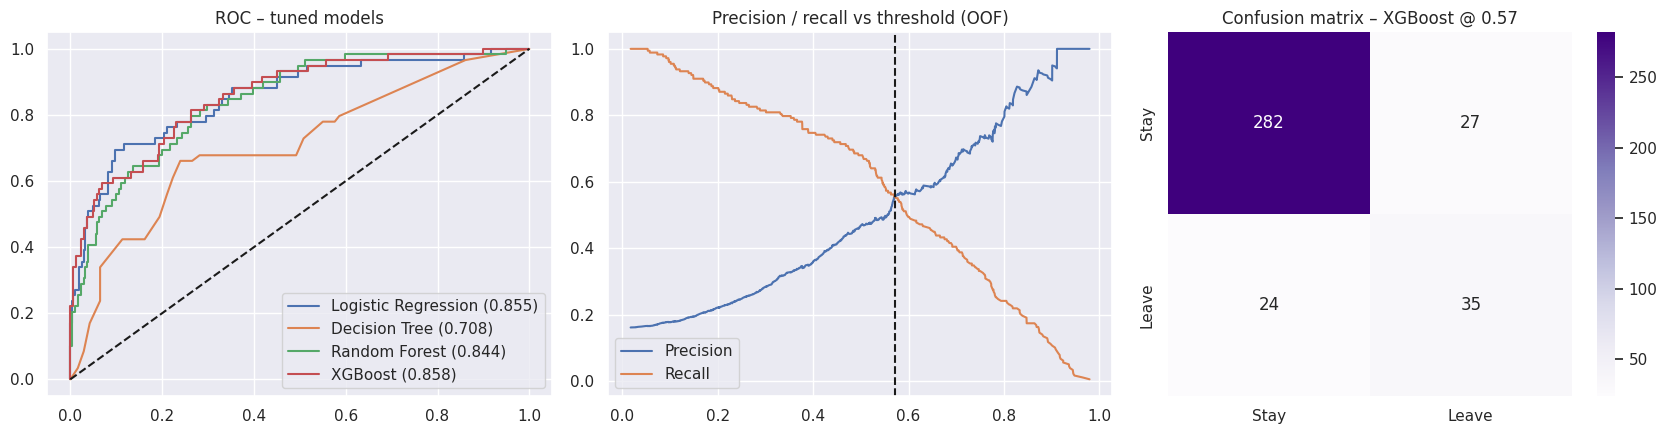

In [8]:
best_name = tuned_df['ROC-AUC'].idxmax(); best_model = tuned[best_name]; print('Best model by ROC-AUC:', best_name)
oof = cross_val_predict(best_model, X_train, y_train, cv=skf10, method='predict_proba')[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
f1s = 2*prec*rec/(prec+rec+1e-9); best_thr = float(thr[np.argmax(f1s[:-1])]); print('Chosen threshold: %.3f' % best_thr)
thr_metrics = evaluate(best_model, X_test, y_test, thr=best_thr)
thr_df = pd.DataFrame({'Default (0.50)': evaluate(best_model, X_test, y_test), f'Tuned ({best_thr:.2f})': thr_metrics}).T.round(3)
thr_df.to_csv('outputs/threshold_metrics.csv'); print(thr_df)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for n, m in tuned.items():
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test)[:,1]); ax[0].plot(fpr, tpr, label=f"{n} ({tuned_rows[n]['ROC-AUC']:.3f})")
ax[0].plot([0,1],[0,1],'k--'); ax[0].legend(); ax[0].set_title('ROC – tuned models')
ax[1].plot(thr, prec[:-1], label='Precision'); ax[1].plot(thr, rec[:-1], label='Recall'); ax[1].axvline(best_thr, color='k', ls='--'); ax[1].legend(); ax[1].set_title('Precision / recall vs threshold (OOF)')
cm = confusion_matrix(y_test, (best_model.predict_proba(X_test)[:,1] >= best_thr).astype(int))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', ax=ax[2], xticklabels=['Stay','Leave'], yticklabels=['Stay','Leave']); ax[2].set_title(f'Confusion matrix – {best_name} @ {best_thr:.2f}')
plt.tight_layout(); plt.savefig('outputs/evaluation.png', dpi=130); plt.show()

## 9. Feature importance (model-based + permutation)

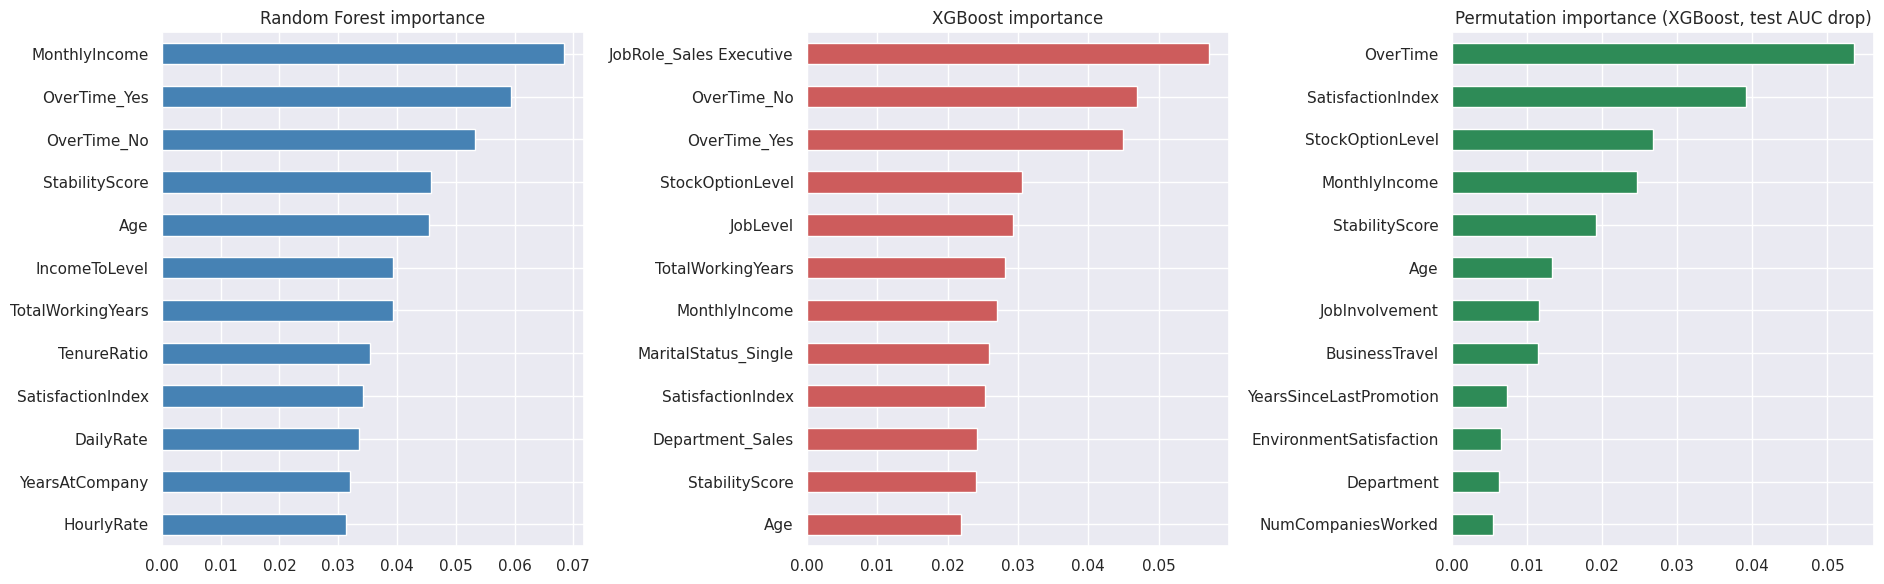

In [9]:
def names(p): return [x.replace('num__','').replace('cat__','') for x in p.named_steps['pre'].get_feature_names_out()]
rf, xg = tuned['Random Forest'], tuned['XGBoost']
imp_rf = pd.Series(rf.named_steps['clf'].feature_importances_, index=names(rf)).sort_values(ascending=False).head(12)
imp_xg = pd.Series(xg.named_steps['clf'].feature_importances_, index=names(xg)).sort_values(ascending=False).head(12)
pi = permutation_importance(best_model, X_test, y_test, scoring='roc_auc', n_repeats=15, random_state=SEED, n_jobs=-1)
imp_pi = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False).head(12)
fig, ax = plt.subplots(1, 3, figsize=(19, 6))
imp_rf[::-1].plot(kind='barh', ax=ax[0], color='steelblue'); ax[0].set_title('Random Forest importance')
imp_xg[::-1].plot(kind='barh', ax=ax[1], color='indianred'); ax[1].set_title('XGBoost importance')
imp_pi[::-1].plot(kind='barh', ax=ax[2], color='seagreen'); ax[2].set_title(f'Permutation importance ({best_name}, test AUC drop)')
plt.tight_layout(); plt.savefig('outputs/feature_importance.png', dpi=130); plt.show()
imp_rf.to_csv('outputs/top_features_rf.csv'); imp_xg.to_csv('outputs/top_features_xgb.csv'); imp_pi.to_csv('outputs/top_features_perm.csv')

In [10]:
print(df.groupby('PerformanceRating')['PercentSalaryHike'].agg(['min','max','count']))
leak_note = 'PerformanceRating is fully determined by PercentSalaryHike in this dataset (rating 4 only when hike >= 15%).'
print(leak_note)

                   min  max  count
PerformanceRating                 
3                   11   19   1244
4                   20   25    226
PerformanceRating is fully determined by PercentSalaryHike in this dataset (rating 4 only when hike >= 15%).


In [12]:
Xr = data.drop(columns=['PerformanceRating','Attrition','PercentSalaryHike']); yr = data['PerformanceRating']
cat_r = Xr.select_dtypes(exclude='number').columns.tolist(); num_r = Xr.select_dtypes(include='number').columns.tolist()
pre_r = lambda sc: ColumnTransformer([('num', StandardScaler() if sc else 'passthrough', num_r), ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_r)])
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.25, random_state=SEED)
reg_models = {
 'Ridge': Pipeline([('pre', pre_r(True)), ('m', Ridge(alpha=30))]),
 'Gradient Boosting Reg.': Pipeline([('pre', pre_r(False)), ('m', GradientBoostingRegressor(n_estimators=150, max_depth=2, learning_rate=0.03, subsample=0.8, random_state=SEED))]),
 'Random Forest Reg.': Pipeline([('pre', pre_r(False)), ('m', RandomForestRegressor(n_estimators=300, min_samples_leaf=10, random_state=SEED, n_jobs=-1))]),
 'XGBoost Reg.': Pipeline([('pre', pre_r(False)), ('m', XGBRegressor(n_estimators=200, learning_rate=0.03, max_depth=2, random_state=SEED))]),
}
kf = KFold(5, shuffle=True, random_state=SEED); rr = {}
for n, m in reg_models.items():
    m.fit(Xr_tr, yr_tr); p = m.predict(Xr_te)
    rr[n] = {'MAE': mean_absolute_error(yr_te, p), 'RMSE': np.sqrt(mean_squared_error(yr_te, p)), 'R2 (test)': r2_score(yr_te, p),
             'R2 (5-fold CV)': cross_validate(m, Xr_tr, yr_tr, cv=kf, scoring='r2')['test_score'].mean()}
reg_df = pd.DataFrame(rr).T.round(3); reg_df.to_csv('outputs/regression_metrics.csv')
mean_mae = mean_absolute_error(yr_te, np.full(len(yr_te), yr_tr.mean())); print('Mean-baseline MAE: %.3f' % mean_mae); reg_df

Mean-baseline MAE: 0.258


,MAE,RMSE,R2 (test),R2 (5-fold CV)
Ridge,0.26,0.364,-0.043,-0.030
Gradient Boosting Reg.,0.26,0.364,-0.044,-0.034
Random Forest Reg.,0.26,0.366,-0.057,-0.010
XGBoost Reg.,0.26,0.366,-0.052,-0.032


In [13]:
best_reg = reg_df['R2 (test)'].idxmax(); m = reg_models[best_reg]
inner = m.named_steps['m']
if hasattr(inner, 'feature_importances_'):
    s = pd.Series(inner.feature_importances_, index=[x.replace('num__','').replace('cat__','') for x in m.named_steps['pre'].get_feature_names_out()]).sort_values(ascending=False).head(10)
    s[::-1].plot(kind='barh', figsize=(6,4), color='goldenrod'); plt.title(f'Top drivers of PerformanceRating ({best_reg})'); plt.tight_layout()
    plt.savefig('outputs/regression_importance.png', dpi=130); plt.show()

## 11. Save summary for the report

In [14]:
summary = {'best_classifier': best_name, 'threshold': best_thr, 'best_params': best_params, 'baseline': baseline.to_dict('index'),
           'tuned': tuned_df.to_dict('index'), 'threshold_metrics': thr_df.to_dict('index'), 'regression': reg_df.to_dict('index'),
           'best_regressor': best_reg, 'regression_mean_mae': mean_mae, 'leak_note': leak_note, 'n_rows': int(len(df)), 'attrition_rate': float(y.mean())}
json.dump(summary, open('outputs/summary.json','w'), indent=2, default=str); print('saved')

saved
